# **Install Packages and imports**

In [1]:
!pip install -q sentencepiece
!pip install -q sacrebleu

import re
import requests
import numpy as np
import pandas as pd
import tensorflow as tf
import sentencepiece as spm

from sklearn.model_selection import train_test_split

# **Dataset Preparation**

In [2]:

english_url = (
    "https://raw.githubusercontent.com/nlpc-uom/"
    "English-Tamil-Parallel-Corpus/master/"
    "En-Ta%20Corpus/En-Ta%20English.txt"
)

tamil_url = (
    "https://github.com/nlpc-uom/"
    "English-Tamil-Parallel-Corpus/raw/master/"
    "En-Ta%20Corpus/En-Ta%20Tamil.txt"
)

english_response = requests.get(english_url)
tamil_response = requests.get(tamil_url)

english_response.raise_for_status()
tamil_response.raise_for_status()

english_lines = english_response.text.splitlines()
tamil_lines = tamil_response.text.splitlines()


english = english_lines[3:]
tamil = tamil_lines[3:]


print("English lines:", len(english))
print("Tamil lines  :", len(tamil))


min_length = min(
    len(english),
    len(tamil)
)

english = english[:min_length]
tamil = tamil[:min_length]


data = pd.DataFrame({
    "english": english,
    "tamil": tamil
})


def clean_text(text):

    text = str(text).strip()

    # Replace multiple spaces with one space
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text


data["english"] = data["english"].apply(
    clean_text
)

data["tamil"] = data["tamil"].apply(
    clean_text
)

# Remove empty sentence pairs

data = data[
    (data["english"] != "") &
    (data["tamil"] != "")
].reset_index(drop=True)


print()
print("Total translation pairs:", len(data))

print()
print("First 10 translation pairs:")
print(
    data.head(10).to_string(index=False)
)

English lines: 8946
Tamil lines  : 8946

Total translation pairs: 8899

First 10 translation pairs:
                                      english                                            tamil
                      Ranaviru Sewa Authority                           ரணவிரு சேவை அதிகார சபை
                           Annual Report 2011                            வருடாந்த அறிக்கை 2011
                           No.301, 4th Floor,                              இல. 301, 4ஆம் மாடி,
                            T.B.Jayah Mawatha                              டி.பி. ஜாயா மாவத்தை
                                   Colombo 10                                      கொழும்பு 10
                                     Contents                                       உள்ளடக்கம்
01. Nation’s gratitude to the name 'Ranaviru' 01. இராணுவ வீரன் எனும் பெயருக்கு தேசத்தின் நன்றி
                                 02. Preamble                                     02. முன்னுரை
                            03. Our Functions

# **Train , test, val split**

In [3]:
train_data, temp_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training   :", len(train_data))
print("Validation :", len(val_data))
print("Testing    :", len(test_data))

Training   : 7119
Validation : 890
Testing    : 890


# **Train our own SentencePiece tokenizers**

In [4]:
with open("english_train.txt", "w", encoding="utf-8") as f:
    for sentence in train_data["english"]:
        f.write(sentence + "\n")

with open("tamil_train.txt", "w", encoding="utf-8") as f:
    for sentence in train_data["tamil"]:
        f.write(sentence + "\n")


spm.SentencePieceTrainer.train(
    input="english_train.txt",
    model_prefix="english_tokenizer",
    vocab_size=4000,
    character_coverage=1.0,
    model_type="bpe"
)

spm.SentencePieceTrainer.train(
    input="tamil_train.txt",
    model_prefix="tamil_tokenizer",
    vocab_size=4000,
    character_coverage=1.0,
    model_type="bpe"
)

english_tokenizer = spm.SentencePieceProcessor(
    model_file="english_tokenizer.model"
)

tamil_tokenizer = spm.SentencePieceProcessor(
    model_file="tamil_tokenizer.model"
)

print("Tokenizers trained.")

Tokenizers trained.


# **Encoding, special tokens and padding**

In [5]:
PAD_ID = 0
SOS_ID = 1
EOS_ID = 2
UNK_ID = 3

MAX_SOURCE_LENGTH = 40
MAX_TARGET_LENGTH = 40


def encode_source(text):
    token_ids = english_tokenizer.encode(
        text,
        out_type=int
    )

    return [token_id + 4 for token_id in token_ids]


def encode_target(text):
    token_ids = tamil_tokenizer.encode(
        text,
        out_type=int
    )

    token_ids = [token_id + 4 for token_id in token_ids]

    return [SOS_ID] + token_ids + [EOS_ID]


def pad_sequence(sequence, max_length):

    if len(sequence) > max_length:

        # Preserve EOS for target sequences
        if sequence[-1] == EOS_ID:
            return sequence[:max_length - 1] + [EOS_ID]

        return sequence[:max_length]

    return sequence + [PAD_ID] * (
        max_length - len(sequence)
    )


def create_decoder_sequences(target_ids):

    decoder_input = target_ids[:-1]
    decoder_output = target_ids[1:]

    return decoder_input, decoder_output


def prepare_batch(data_batch):

    encoder_inputs = []
    decoder_inputs = []
    decoder_outputs = []

    for _, row in data_batch.iterrows():

        source_ids = encode_source(
            row["english"]
        )

        target_ids = encode_target(
            row["tamil"]
        )

        decoder_input, decoder_output = create_decoder_sequences(
            target_ids
        )

        source_ids = pad_sequence(
            source_ids,
            MAX_SOURCE_LENGTH
        )

        decoder_input = pad_sequence(
            decoder_input,
            MAX_TARGET_LENGTH
        )

        decoder_output = pad_sequence(
            decoder_output,
            MAX_TARGET_LENGTH
        )

        encoder_inputs.append(source_ids)
        decoder_inputs.append(decoder_input)
        decoder_outputs.append(decoder_output)

    return (
        np.array(encoder_inputs, dtype=np.int32),
        np.array(decoder_inputs, dtype=np.int32),
        np.array(decoder_outputs, dtype=np.int32)
    )


print("Encoding functions ready.")

Encoding functions ready.


# **Transformer parameters and positional encoding**

In [6]:
EMBEDDING_DIM = 256
NUM_HEADS = 8
FEED_FORWARD_DIM = 1024

NUM_ENCODER_BLOCKS = 3
NUM_DECODER_BLOCKS = 3

BATCH_SIZE = 32
EPOCHS = 30

ENGLISH_VOCAB_SIZE = english_tokenizer.get_piece_size() + 4
TAMIL_VOCAB_SIZE = tamil_tokenizer.get_piece_size() + 4


def positional_encoding(max_length, embedding_dim):

    position = np.arange(max_length)[:, np.newaxis]

    dimension = np.arange(embedding_dim)[np.newaxis, :]

    angle_rates = 1 / np.power(
        10000,
        (2 * (dimension // 2)) /
        np.float32(embedding_dim)
    )

    angle_rads = position * angle_rates

    encoding = np.zeros(
        (max_length, embedding_dim)
    )

    encoding[:, 0::2] = np.sin(
        angle_rads[:, 0::2]
    )

    encoding[:, 1::2] = np.cos(
        angle_rads[:, 1::2]
    )

    return tf.cast(
        encoding,
        tf.float32
    )


source_pos_encoding = positional_encoding(
    MAX_SOURCE_LENGTH,
    EMBEDDING_DIM
)

target_pos_encoding = positional_encoding(
    MAX_TARGET_LENGTH,
    EMBEDDING_DIM
)

print("English vocabulary:", ENGLISH_VOCAB_SIZE)
print("Tamil vocabulary:", TAMIL_VOCAB_SIZE)

English vocabulary: 4004
Tamil vocabulary: 4004


# **Transformer Encoder**

In [7]:
class TransformerEncoderBlock(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        embedding_dim,
        num_heads,
        feed_forward_dim
    ):
        super().__init__()

        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embedding_dim // num_heads
        )

        self.feed_forward = tf.keras.Sequential([
            tf.keras.layers.Dense(
                feed_forward_dim,
                activation="relu"
            ),
            tf.keras.layers.Dense(
                embedding_dim
            )
        ])

        self.norm1 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

    def call(
        self,
        inputs,
        training=False
    ):

        attention_output = self.attention(
            query=inputs,
            key=inputs,
            value=inputs,
            training=training
        )

        x = self.norm1(
            inputs + attention_output
        )

        feed_forward_output = self.feed_forward(
            x,
            training=training
        )

        output = self.norm2(
            x + feed_forward_output
        )

        return output

# **Transformer Decoder**

In [8]:
class TransformerDecoderBlock(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        embedding_dim,
        num_heads,
        feed_forward_dim
    ):
        super().__init__()

        self.self_attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embedding_dim // num_heads
        )

        self.cross_attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embedding_dim // num_heads
        )

        self.feed_forward = tf.keras.Sequential([
            tf.keras.layers.Dense(
                feed_forward_dim,
                activation="relu"
            ),
            tf.keras.layers.Dense(
                embedding_dim
            )
        ])

        self.norm1 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm3 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

    def call(
        self,
        decoder_inputs,
        encoder_output,
        causal_mask,
        training=False
    ):

        # Masked self-attention
        self_attention_output = self.self_attention(
            query=decoder_inputs,
            key=decoder_inputs,
            value=decoder_inputs,
            attention_mask=causal_mask,
            training=training
        )

        x = self.norm1(
            decoder_inputs + self_attention_output
        )

        # Cross-attention
        cross_attention_output = self.cross_attention(
            query=x,
            key=encoder_output,
            value=encoder_output,
            training=training
        )

        x = self.norm2(
            x + cross_attention_output
        )

        # Feed-forward
        feed_forward_output = self.feed_forward(
            x,
            training=training
        )

        output = self.norm3(
            x + feed_forward_output
        )

        return output


def create_causal_mask(sequence_length):

    return tf.linalg.band_part(
        tf.ones(
            (sequence_length, sequence_length)
        ),
        -1,
        0
    )

# **Transformer Model**

In [9]:
class Transformer(tf.keras.Model):

    def __init__(
        self,
        english_vocab_size,
        tamil_vocab_size,
        embedding_dim,
        num_heads,
        feed_forward_dim,
        num_encoder_blocks,
        num_decoder_blocks
    ):
        super().__init__()

        # English embedding
        self.encoder_embedding = tf.keras.layers.Embedding(
            input_dim=english_vocab_size,
            output_dim=embedding_dim
        )

        # Tamil embedding
        self.decoder_embedding = tf.keras.layers.Embedding(
            input_dim=tamil_vocab_size,
            output_dim=embedding_dim
        )

        # Encoder blocks
        self.encoder_blocks = [
            TransformerEncoderBlock(
                embedding_dim,
                num_heads,
                feed_forward_dim
            )
            for _ in range(num_encoder_blocks)
        ]

        # Decoder blocks
        self.decoder_blocks = [
            TransformerDecoderBlock(
                embedding_dim,
                num_heads,
                feed_forward_dim
            )
            for _ in range(num_decoder_blocks)
        ]

        # Final vocabulary prediction
        self.output_layer = tf.keras.layers.Dense(
            tamil_vocab_size
        )

    def call(
        self,
        inputs,
        training=False
    ):

        # Unpack inputs
        encoder_inputs = inputs[0]
        decoder_inputs = inputs[1]

        # Encoder

        encoder_x = self.encoder_embedding(
            encoder_inputs
        )

        encoder_x = (
            encoder_x +
            source_pos_encoding
        )

        for block in self.encoder_blocks:

            encoder_x = block(
                encoder_x,
                training=training
            )
        # Decoder

        decoder_x = self.decoder_embedding(
            decoder_inputs
        )

        decoder_x = (
            decoder_x +
            target_pos_encoding
        )

        # Causal mask
        causal_mask = create_causal_mask(
            tf.shape(decoder_inputs)[1]
        )

        for block in self.decoder_blocks:

            decoder_x = block(
                decoder_x,
                encoder_x,
                causal_mask,
                training=training
            )

        # Output

        logits = self.output_layer(
            decoder_x
        )

        return logits


  # define transformer
transformer = Transformer(
    english_vocab_size=ENGLISH_VOCAB_SIZE,
    tamil_vocab_size=TAMIL_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    feed_forward_dim=FEED_FORWARD_DIM,
    num_encoder_blocks=NUM_ENCODER_BLOCKS,
    num_decoder_blocks=NUM_DECODER_BLOCKS
)

print("Complete Transformer created.")

Complete Transformer created.


# **Loss , Optimizer and Dataset Creation**

In [10]:
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

def masked_loss(y_true, y_pred):

    loss = loss_function(
        y_true,
        y_pred
    )

    mask = tf.cast(
        tf.not_equal(y_true, PAD_ID),
        loss.dtype
    )

    loss = loss * mask

    return tf.reduce_sum(loss) / tf.reduce_sum(mask)


def create_dataset(data):

    encoder_inputs, decoder_inputs, decoder_outputs = prepare_batch(
        data
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            (
                encoder_inputs,
                decoder_inputs
            ),
            decoder_outputs
        )
    )

    dataset = dataset.shuffle(
        len(encoder_inputs)
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    return dataset


train_dataset = create_dataset(train_data)
val_dataset = create_dataset(val_data)
test_dataset = create_dataset(test_data)

print("Datasets created.")

Datasets created.


# **Transformer Training**

In [11]:
# Reduce learning rate when validation loss stops improving
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Compile the Transformer
transformer.compile(
    optimizer=optimizer,
    loss=masked_loss
)

# Train the model
history = transformer.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[
        reduce_lr,
        early_stopping
    ],
    verbose=1
)

Epoch 1/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 69s 128ms/step - loss: 2.8526 - val_loss: 2.0277 - learning_rate: 1.0000e-04
Epoch 2/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 2.0041 - val_loss: 1.8871 - learning_rate: 1.0000e-04
Epoch 3/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 1.9005 - val_loss: 1.8295 - learning_rate: 1.0000e-04
Epoch 4/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 1.8386 - val_loss: 1.7827 - learning_rate: 1.0000e-04
Epoch 5/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 1.7820 - val_loss: 1.7409 - learning_rate: 1.0000e-04
Epoch 6/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 1.7143 - val_loss: 1.6761 - learning_rate: 1.0000e-04
Epoch 7/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 1.6364 - val_loss: 1.6173 - learning_rate: 1.0000e-04
Epoch 8/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 1.5522 - val_loss: 1.5614 - learning_rate: 1.0000e-04
Epoch 9/30
223/223 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 1.4725 - val_loss

# **Model Testing**

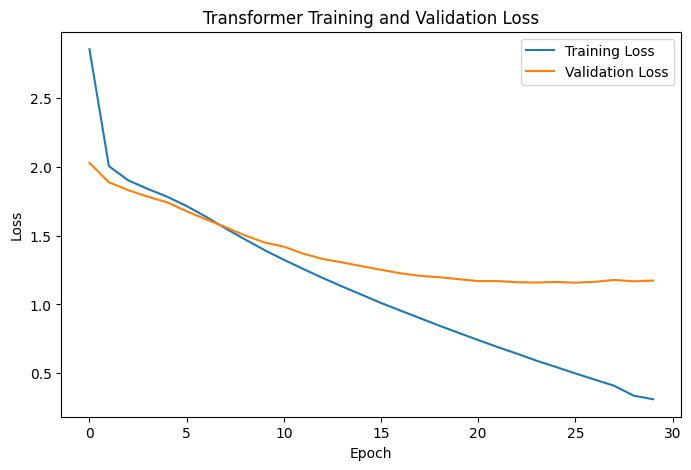

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Training and Validation Loss")
plt.legend()
plt.show()

In [13]:
def translate_sentence(sentence, beam_width=3):

    # Convert English sentence to token IDs
    encoder_ids = encode_source(sentence)

    # Pad English input
    encoder_ids = pad_sequence(
        encoder_ids,
        MAX_SOURCE_LENGTH
    )

    encoder_input = tf.constant(
        [encoder_ids],
        dtype=tf.int32
    )

    # Each beam contains:
    # (generated token IDs, score)
    beams = [
        ([SOS_ID], 0.0)
    ]

    for step in range(MAX_TARGET_LENGTH - 1):

        all_candidates = []

        for decoder_ids, score in beams:

            # If sentence already ended,
            # keep it unchanged
            if decoder_ids[-1] == EOS_ID:
                all_candidates.append(
                    (decoder_ids, score)
                )
                continue

            # Prepare decoder input
            decoder_input = tf.constant(
                [
                    pad_sequence(
                        decoder_ids,
                        MAX_TARGET_LENGTH
                    )
                ],
                dtype=tf.int32
            )

            # Get model predictions
            predictions = transformer(
                [encoder_input, decoder_input],
                training=False
            )

            # Get predictions for current position
            logits = predictions[
                0,
                len(decoder_ids) - 1
            ]

            # Convert logits to probabilities
            probabilities = tf.nn.softmax(
                logits
            )

            # Select top beam_width tokens
            top_probabilities, top_tokens = tf.math.top_k(
                probabilities,
                k=beam_width
            )

            for probability, token in zip(
                top_probabilities.numpy(),
                top_tokens.numpy()
            ):

                token = int(token)

                # Ignore PAD token
                if token == PAD_ID:
                    continue

                new_sequence = (
                    decoder_ids + [token]
                )

                # Add log probability
                new_score = (
                    score +
                    np.log(
                        float(probability) + 1e-10
                    )
                )

                all_candidates.append(
                    (
                        new_sequence,
                        new_score
                    )
                )

        # Keep the best beam_width sequences
        all_candidates.sort(
            key=lambda x: x[1],
            reverse=True
        )

        beams = all_candidates[:beam_width]

        # Stop if every beam has ended
        if all(
            sequence[-1] == EOS_ID
            for sequence, score in beams
        ):
            break

    # Select best final sequence
    best_sequence = max(
        beams,
        key=lambda x: x[1]
    )[0]

    # Remove SOS and special tokens
    tamil_ids = [
        token_id - 4
        for token_id in best_sequence[1:]
        if token_id >= 4
        and token_id != EOS_ID
    ]

    # Convert token IDs back to Tamil
    tamil_text = tamil_tokenizer.decode(
        tamil_ids
    )

    return tamil_text


print("Beam search translation function is ready!")

Beam search translation function is ready!


In [14]:
for i in range(10):

    english_sentence = test_data.loc[i, "english"]
    actual_tamil = test_data.loc[i, "tamil"]

    predicted_tamil = translate_sentence(
        english_sentence
    )

    print("English   :", english_sentence)
    print("Actual    :", actual_tamil)
    print("Predicted :", predicted_tamil)
    print("-" * 60)

English   : Accordingly, arrangements were made to provide training for around 5456 public officers through 186 classes by the Institute in the year 2015.
Actual    : அந்த வகையில், நிறுவனமானது 2015 ஆம் ஆண்டில் 186 வகுப்புகளை நடாத்தியதன் மூலம் ஏறக்குறைய 5446 அரச உத்தியோகத்தர்களுக்கு மொழிப் பயிற்சி வழங்குவதற்கான ஏற்பாடுகளை ஒழுங்கமைத்தது.
Predicted : அந்த வகையில், 2015 வரவு செலவுத்திட்ட மதிப்பீடுகளைத் தயாரிப்பதற்கான வழிகாட்டல்கள் தொடர்பாக ஆராய்ந்து பார்க்கப்பட வேண்டியுள்ளது.
------------------------------------------------------------
English   : Private Hospitals
Actual    : தனியார் வைத்தியசாலை
Predicted : தனியார் வைத்தியசாலை
------------------------------------------------------------
English   : Evaluation - Provincial Ministry
Actual    : கண்காணிப்பு மற்றும் மதிப்பீடு - மாகாண அமைச்சு
Predicted : கண்காணிப்பு மற்றும் மதிப்பீடு - மாகாண அமைச்சு
------------------------------------------------------------
English   : Concessionary Loan Project
Actual    : நிவாரணக் கடன் திட்டம்
Predicted : 

In [ ]:


import sacrebleu

predictions = []
references = []

for i in range(300):

    english_sentence = test_data.loc[i, "english"]
    actual_tamil = test_data.loc[i, "tamil"]

    predicted_tamil = translate_sentence(
        english_sentence
    )

    predictions.append(predicted_tamil)
    references.append(actual_tamil)

bleu = sacrebleu.corpus_bleu(
    predictions,
    [references]
)

print("BLEU Score:", bleu.score)